# ARTE4110U Challenge 3: Shallow and Deep Networks

Submit one completed Jupyter notebook on Canvas. Write explanations in the Markdown cells beside your work; no separate report is required.

## Purpose

Compare a shallow and a deep ReLU network with the **same number of trainable parameters**. Examine the shapes they can represent, then train both in **PyTorch** and compare what they actually learn. These are different questions.

This challenge follows the linear-regression challenge and the lecture on composition, depth, width, and linear regions. Use `torch.nn` to build the models and PyTorch autograd to train them. You do **not** need to write a network or derive backpropagation from scratch.

**Libraries:** NumPy, Matplotlib, and PyTorch. If necessary, install them in your notebook environment. Keep the provided target, data split, architectures, and training settings unchanged. Use validation MSE to select runs, and check the test set only after selection. Follow the course policy when using AI tools.


## 1. A target made by repeated folding

For $x\in[0,1]$, define $T(x)=1-|2x-1|$. The target is $f(x)=T(T(T(x)))$. Each application folds the previous output, as in the lecture. The code below supplies the target and one fixed training, validation, and test split. **Do not change it.**


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn


def fold(z):
    return 1.0 - np.abs(2.0 * z - 1.0)


def target(z):
    z = np.asarray(z, dtype=float)
    for _ in range(3):
        z = fold(z)
    return z


rng = np.random.default_rng(42)
x_train = rng.uniform(0.0, 1.0, size=(160, 1))
x_val = rng.uniform(0.0, 1.0, size=(80, 1))
x_test = rng.uniform(0.0, 1.0, size=(160, 1))
y_train = target(x_train[:, 0])
y_val = target(x_val[:, 0])
y_test = target(x_test[:, 0])

x_grid = np.linspace(0.0, 1.0, 1001)
y_grid = target(x_grid)
assert x_train.shape == (160, 1) and y_train.shape == (160,)


**TODO:** Plot $T(x)$, $T(T(x))$, and $T(T(T(x)))$ over the supplied grid. Give each curve a label. Count the straight-line pieces in the final target (count pieces, not just peaks).


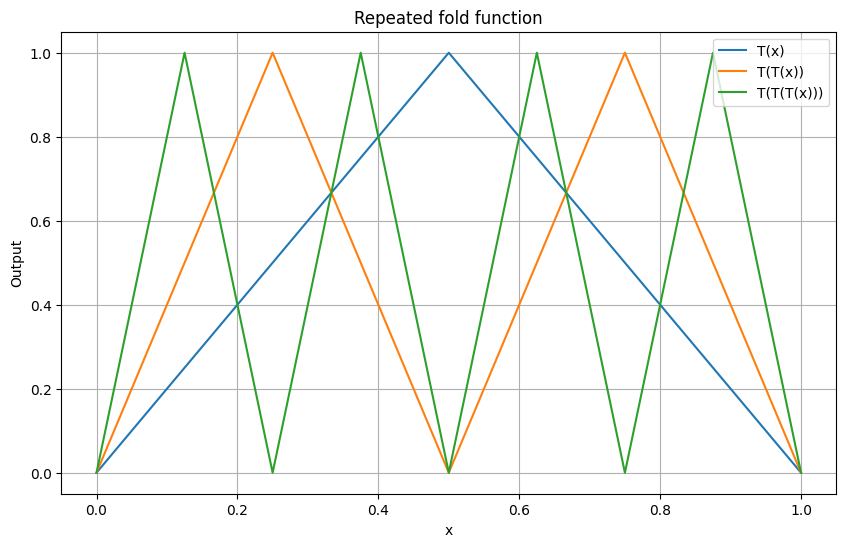

In [4]:
# TODO: create the three curves using fold and plot them on labeled axes.
fold1 = fold(x_grid)
fold2 = fold(fold1)
fold3 = fold(fold2)
# TODO: print how many straight-line pieces you see in the final target.
plt.figure(figsize=(10,6))
plt.plot(x_grid, fold1, label="T(x)")
plt.plot(x_grid, fold2, label="T(T(x))")
plt.plot(x_grid, fold3, label="T(T(T(x)))")

plt.xlabel("x")
plt.ylabel("Output")
plt.title("Repeated fold function")
plt.legend()
plt.grid(True)

plt.show()

**Your observation:** How does applying the same fold three times change the shape? State the number of straight-line pieces in $f(x)$.

_Write your answer here._

Ans: Each time we fold, we increase the number of peaks and straight-line regions, each call to fold() we double the number of linear pieces. It goest from 2 -> 4 -> 8 pieces.


## 2. Compare architectures under one parameter budget

Both networks have one scalar input, one scalar output, ReLU hidden units, and a **linear output**:

| Network | Hidden-layer widths | Depth |
|---|---|---|
| Shallow | `(6,)` | 1 hidden layer |
| Deep | `(2, 2, 2)` | 3 hidden layers |

Count weights and biases for every transition and verify that the totals match. A shallow network with six ReLU units can create at most six bends, or seven straight-line pieces, on a one-dimensional input. Compare this limit with the target from Section 1.

To see why depth can help here, one fold can be written as $T(z)=2\operatorname{ReLU}(z)-4\operatorname{ReLU}(z-0.5)$ on $[0,1]$. Three two-unit hidden layers can compose that fold three times. You will test the networks **through training in PyTorch**; you do not have to set their weights by hand.


In [5]:
def parameter_count(hidden_widths, input_dim=1, output_dim=1):
    # TODO: count the weights and biases from input through every hidden layer.
    # TODO: add the weights and biases from the final hidden layer to the output.
    total = 0
    width_in = input_dim
    for width_out in hidden_widths:
      total += width_in * width_out
      total += width_out
      width_in = width_out

    total += width_in * output_dim
    total += output_dim

    return total


shallow_widths = (6,)
deep_widths = (2, 2, 2)
print('Shallow parameters:', parameter_count(shallow_widths))
print('Deep parameters:', parameter_count(deep_widths))


Shallow parameters: 19
Deep parameters: 19


**Your calculation:** Show the weights, biases, and total parameters for both networks. How many straight-line pieces does the target have? Explain why the number of pieces is relevant to the shallow network's ability to represent this target exactly.

_Write your answer here._

The shallow network has 12 parameters from input-to-hidden layer and 7 from the hidden-to-output layer, for a total of 19. The deep network has 4, 6, 6, and 3 parameters across its four linear transitions, also totaling 19. Both architectures use the same parameter budget. The target has 8 straight-line pieces. A one-hidden-layer network with 6 relu units can create at most 6 bends, or 7 straight-line pieces, so it cannot represent the target exactly. The deeper network can use composition across layers to produce more linear regions despite having the same total number of parameters.


## 3. Build the networks with PyTorch

Use `nn.Linear` and `nn.ReLU` to construct the architectures above. A model with widths `(6,)` should be `Linear(1, 6)`, `ReLU`, `Linear(6, 1)`. A model with widths `(2, 2, 2)` repeats `Linear` and `ReLU` for three hidden layers before its final `Linear(2, 1)`. The output has no ReLU.

The helper below builds either architecture using PyTorch modules. Inspect both models and confirm the trainable parameter totals using `sum(p.numel() for p in model.parameters())`. No manual NumPy forward pass is required.


In [7]:
def make_model(hidden_widths):
    layers = []
    width_in = 1
    for width_out in hidden_widths:
        layers.extend([nn.Linear(width_in, width_out), nn.ReLU()])
        width_in = width_out
    layers.append(nn.Linear(width_in, 1))
    return nn.Sequential(*layers)


shallow_widths = (6,)
deep_widths = (2, 2, 2)
architectures = {'Shallow': shallow_widths, 'Deep': deep_widths}

# TODO: instantiate and print both models.
# TODO: print the PyTorch parameter count for each model and compare it
#       against your manual calculation in Section 2.
shallow_model = make_model(shallow_widths)
deep_model = make_model(deep_widths)

print("Shallow model: ")
print(shallow_model)

print("\nDeep model: ")
print(deep_model)

shallow_count = sum(p.numel() for p in shallow_model.parameters())
deep_count = sum(p.numel() for p in deep_model.parameters())

print("Shallow parameter count:", shallow_count)
print("Deep parameter count:", deep_count)

Shallow model: 
Sequential(
  (0): Linear(in_features=1, out_features=6, bias=True)
  (1): ReLU()
  (2): Linear(in_features=6, out_features=1, bias=True)
)

Deep model: 
Sequential(
  (0): Linear(in_features=1, out_features=2, bias=True)
  (1): ReLU()
  (2): Linear(in_features=2, out_features=2, bias=True)
  (3): ReLU()
  (4): Linear(in_features=2, out_features=2, bias=True)
  (5): ReLU()
  (6): Linear(in_features=2, out_features=1, bias=True)
)
Shallow parameter count: 19
Deep parameter count: 19


**Your observation:** Which model has more hidden layers? Do they have the same number of trainable parameters? State both counts.

_Write your answer here._

The deep model has more hidden layers: it has three, while the shallow model has one. Despite the difference in depth both mhave 19 trainable parameters, this confirms that the comparison uses the same parameter budget, so differences in representational ability are due to architecture and depth rather than simply having more parameters.


## 4. Train both models in PyTorch

The supplied NumPy data use shapes `(N, 1)` for inputs and `(N,)` for targets. Convert the targets to `(N, 1)` so they match the model output. Use `torch.float32` throughout.

Implement the training loop you have practiced: create the model, use `nn.MSELoss` and `torch.optim.Adam`, clear gradients, compute the training loss, call `backward()`, and update the parameters. Record **training and validation MSE after each epoch**. Validation runs under `torch.no_grad()` and never updates weights.

Use the **same** learning rate (`0.01`), epochs (`1500`), full training set, and seeds (`0, 1, 2`) for both architectures. Different architectures cannot have identical initial weight tensors, but using the same list of seeds gives each the same number of attempts. Keep all six runs, including weak ones.


In [15]:
X_train = torch.tensor(x_train, dtype=torch.float32)
Y_train = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
X_val = torch.tensor(x_val, dtype=torch.float32)
Y_val = torch.tensor(y_val.reshape(-1, 1), dtype=torch.float32)
X_test = torch.tensor(x_test, dtype=torch.float32)
Y_test = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)
X_grid = torch.tensor(x_grid.reshape(-1, 1), dtype=torch.float32)


def train_one(hidden_widths, seed, epochs=1500, learning_rate=0.01):
    torch.manual_seed(seed)
    model = make_model(hidden_widths)
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    train_history, val_history = [], []

    for epoch in range(epochs):
        model.train()
        # TODO: clear gradients, predict on X_train, calculate MSE,
        #       call backward(), then take an optimizer step.
        optimizer.zero_grad()
        pred = model(X_train)
        loss = loss_fn(pred, Y_train)

        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            # TODO: evaluate and append training and validation MSE
            #       AFTER the update. Use .item() to record Python numbers.
            train_pred = model(X_train)
            val_pred = model(X_val)

            train_mse = loss_fn(train_pred, Y_train)
            val_mse = loss_fn(val_pred, Y_val)

            train_history.append(train_mse.item())
            val_history.append(val_mse.item())

    return model, train_history, val_history


# TODO: call train_one for BOTH architectures for ALL seeds (0, 1, 2).
# Store each model and its two loss histories for the next sections.
results = {}
for name, widths in architectures.items():
  results[name] = {}

  for seed in [0, 1, 2]:
    model, train_history, val_history = train_one(widths, seed)

    results[name][seed] = {
        "model": model,
        "train_history": train_history,
        "val_history": val_history
    }

## 5. Compare training and validation results

Make a table with one row per run: architecture, seed, parameter count, final training MSE, and final validation MSE. Plot the training and validation loss histories for at least one run of each architecture. Label the curves and axes.

Select **one run per architecture** using its lowest final validation MSE. After choosing, calculate test MSE for each selected model exactly once. Plot their predictions and the true target on the same dense `x_grid`; show the training examples as light points. Do not use test performance to change the selected seeds.


,Architecture,Seed,Parameter Count,Final Train MSE,Final Validation MSE
0,Shallow,0,19,0.068287,0.089216
1,Shallow,1,19,0.064714,0.085937
2,Shallow,2,19,0.068287,0.089216
3,Deep,0,19,0.069358,0.090466
4,Deep,1,19,0.069358,0.090466
5,Deep,2,19,0.068287,0.089232


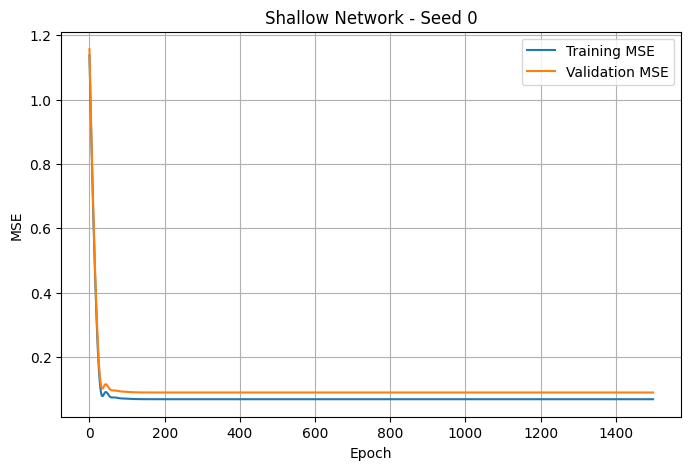

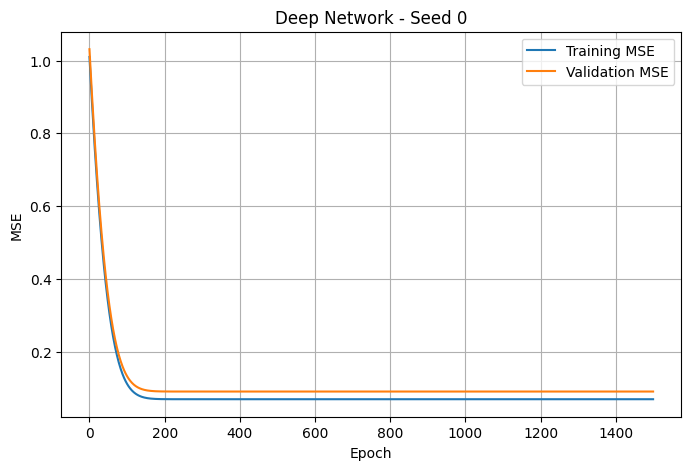

Selected seeds:
Shallow: 1
Deep: 2


,Architecture,Selected Seed,Test MSE
0,Shallow,1,0.078863
1,Deep,2,0.083204


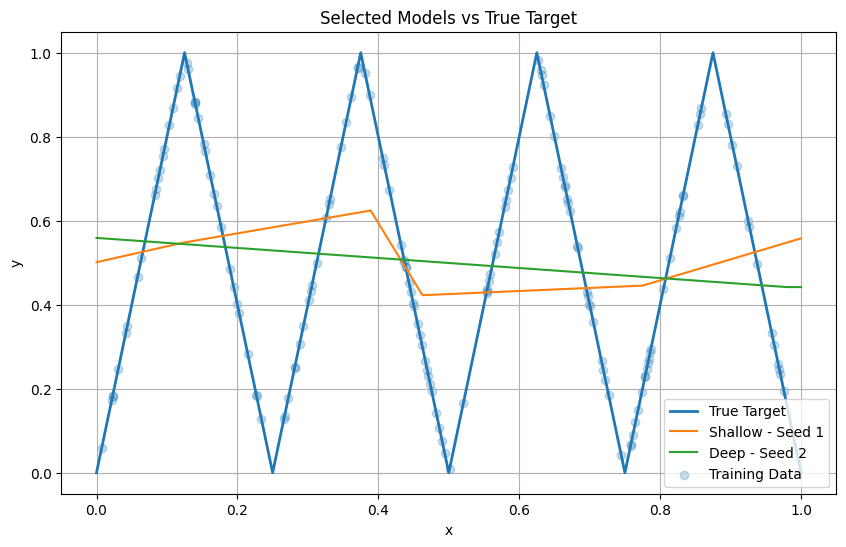

In [16]:
import pandas as pd

rows = []

for name, widths in architectures.items():
    for seed in [0, 1, 2]:
        run = results[name][seed]

        rows.append({
            "Architecture": name,
            "Seed": seed,
            "Parameter Count": parameter_count(widths),
            "Final Train MSE": run["train_history"][-1],
            "Final Validation MSE": run["val_history"][-1]
        })

results_df = pd.DataFrame(rows)
display(results_df)


run = results["Shallow"][0]

plt.figure(figsize=(8, 5))
plt.plot(run["train_history"], label="Training MSE")
plt.plot(run["val_history"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Shallow Network - Seed 0")
plt.legend()
plt.grid(True)
plt.show()



run = results["Deep"][0]

plt.figure(figsize=(8, 5))
plt.plot(run["train_history"], label="Training MSE")
plt.plot(run["val_history"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Deep Network - Seed 0")
plt.legend()
plt.grid(True)
plt.show()

best_seeds = {}

for name in architectures:
    best_seed = min(
        [0, 1, 2],
        key=lambda seed: results[name][seed]["val_history"][-1]
    )

    best_seeds[name] = best_seed

print("Selected seeds:")
print("Shallow:", best_seeds["Shallow"])
print("Deep:", best_seeds["Deep"])

selected_rows = []

for name in architectures:
    seed = best_seeds[name]
    model = results[name][seed]["model"]

    model.eval()

    with torch.no_grad():
        test_pred = model(X_test)
        test_mse = nn.MSELoss()(test_pred, Y_test).item()

    selected_rows.append({
        "Architecture": name,
        "Selected Seed": seed,
        "Test MSE": test_mse
    })

selected_df = pd.DataFrame(selected_rows)
display(selected_df)


predictions = {}

for name in architectures:
    seed = best_seeds[name]
    model = results[name][seed]["model"]

    model.eval()

    with torch.no_grad():
        pred = model(X_grid)

    predictions[name] = pred.squeeze().numpy()

plt.figure(figsize=(10, 6))

plt.plot(
    x_grid,
    y_grid,
    label="True Target",
    linewidth=2
)

plt.plot(
    x_grid,
    predictions["Shallow"],
    label=f"Shallow - Seed {best_seeds['Shallow']}"
)

plt.plot(
    x_grid,
    predictions["Deep"],
    label=f"Deep - Seed {best_seeds['Deep']}"
)

plt.scatter(
    x_train[:, 0],
    y_train,
    alpha=0.25,
    label="Training Data"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Selected Models vs True Target")
plt.legend()
plt.grid(True)

plt.show()

## 6. Interpret your results

Answer briefly in this notebook:

1. The target has repeated folds. Explain why the six-unit shallow network has a limitation for **exactly** representing this target. What did you see when you plotted its learned prediction?
2. Which architecture had lower validation and test MSE in **your runs**? Cite your table. If the deeper model did not win, explain why representational ability does not guarantee that training will find a good set of weights.
3. Compare the loss histories. Did any run stall, improve steadily, or change quickly at first? Use a curve as evidence.
4. Why does a result on this constructed one-dimensional target not establish that deeper networks always generalize better on real datasets?

_Write your answers here._

1. The target function has 8 straight-line pieces because we folded 3x. The shallow network has only 6 ReLU units, so it can create at most 6 bends, which means at most 7 straight-line pieces. Therefore, the shallow network cannot represent the target exactly. In the prediction plot, the shallow model approximates the target, but it cannot reproduce perfectly.

2. In my runs, the shallow network achieved both a lower validation MSE and a lower test MSE than the deep network. The selected shallow model used seed 1 and had a validation MSE of 0.085937 and test MSE of 0.078863. The selected deep model used seed 2 and had a validation MSE of 0.089232 and test MSE of 0.083204. Although the deep network has enough representational capacity to model the repeated folds, this does not guarantee that training will find the required weights. Neural-network optimization depends on the initial weights and the optimization process, so a model can have the theoretical ability to represent a function but still converge to a poorer solution.

3. In the loss histories, both models improved quickly during the early epochs and then stalled. For shallow seed 0, the loss dropped very rapidly near the beginning and reached a nearly flat value relatively early. Deep seed 0 decreased more gradually, but it also eventually flattened at approximately the same range of MSE. After roughly the first 100-200 epochs, neither plotted run showed much additional improvement. The validation loss also remained slightly above the training loss for both models.

4. This experiment does not establish that deeper networks always generalize better because it uses a specially constructed one-dimensional target based on repeated folds. The target was deliberately chosen to demonstrate how composition and depth can affect representational ability. Real datasets can have much higher dimensionality, noise, different structures, and different amounts of training data. Performance also depends on optimization, initialization, architecture, hyperparameters, and other training choices. Therefore, this experiment only demonstrates properties of these architectures on this particular target, rather than proving that deeper networks are always better.

## Completion checklist

- [x] Plotted one, two, and three folds; counted the target's straight-line pieces.
- [x] Counted parameters by layer for both architectures.
- [x] Built and inspected both models with PyTorch modules.
- [x] Trained both architectures with all three seeds under the same settings.
- [x] Plotted loss histories and compared all six validation results.
- [x] Selected models on validation results, then reported test MSE and prediction plots.
- [x] Answered the comparison questions in Markdown cells.

Submit the completed notebook individually on Canvas.
